# 02 — Backtest of the daily forecasts (Phase 5)

Inputs: `data/processed/backtest/` built by `make backtest` (`idf_crowding.models.backtest`).
Rolling origin: 12 monthly origins, horizons 1–60 days, training from 2022-01-01, time splits
only. Flagged station-days (quality flags, network disruption days, station closures) are left
out of training and scoring. `short_pass_share` and `station_type` are frozen at each origin.
Section 8 shows the 80 % intervals and busy-day probabilities (option B).
Weather is the **observed** weather: real use only has forecasts up to ~16 days ahead.
Tables come from `idf_crowding.viz.backtest` / `models.metrics`; this notebook only plots.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from idf_crowding.config import load_config
from idf_crowding.viz import backtest as vb

DATA = load_config()["paths"]["data_dir"]
BT = f"{DATA}/processed/backtest"
pred = pl.read_parquet(f"{BT}/predictions.parquet")
metrics = pl.read_parquet(f"{BT}/metrics.parquet")
importance = pl.read_parquet(f"{BT}/importance.parquet")
stations = pl.read_parquet(f"{DATA}/processed/stations.parquet")
names = dict(
    zip(stations["station_id"], stations["ref_name"].fill_null(stations["label"]), strict=True)
)
intervals = pl.read_parquet(f"{BT}/intervals.parquet")
MODELS = ["naive_4w", "daytype_12m", "lgbm"]
COLORS = {"naive_4w": "#999999", "daytype_12m": "#e67e22", "lgbm": "#1f4e79"}
long = vb.long_scored(pred, MODELS)
pl.Config.set_tbl_rows(30)

polars.config.Config

## 1. Overall errors (station level and network daily totals)

In [2]:
metrics.filter(pl.col("dimension") == "overall").select(
    "level", "model", "n", "wape", "mae", "mape"
)

level,model,n,wape,mae,mape
str,str,u32,f64,f64,f64
"""station""","""daytype_12m""",505801,0.122644,1055.643314,0.142363
"""station""","""lgbm""",505801,0.08964,771.563003,0.119407
"""station""","""naive_4w""",505801,0.160865,1384.631004,0.21774
"""network""","""daytype_12m""",714,0.08567,522372.881942,0.091613
"""network""","""lgbm""",714,0.050812,309824.364141,0.057512
"""network""","""naive_4w""",714,0.129629,790413.318277,0.153178


## 2. WAPE by horizon (all origins and stations)

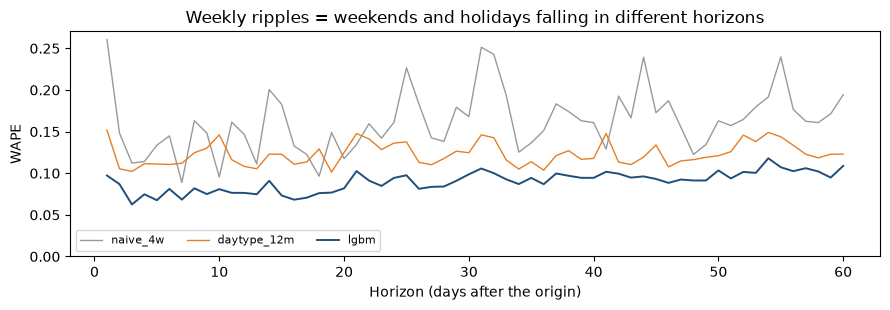

In [3]:
h = vb.wape_by_horizon(long)
fig, ax = plt.subplots(figsize=(9, 3.2))
for m in MODELS:
    d = h.filter(pl.col("model") == m)
    ax.plot(d["horizon"], d["wape"], label=m, color=COLORS[m], lw=1.4 if m == "lgbm" else 1)
ax.set_xlabel("Horizon (days after the origin)")
ax.set_ylabel("WAPE")
ax.set_ylim(0)
ax.legend(ncol=4, fontsize=8)
ax.set_title("Weekly ripples = weekends and holidays falling in different horizons")
plt.tight_layout()

## 3. WAPE by station type × horizon bucket

group,daytype_12m,lgbm,naive_4w
str,f64,f64,f64
"""origin × 1-7""",0.133575,0.086134,0.155337
"""origin × 8-28""",0.148023,0.085767,0.161365
"""origin × 29-60""",0.155164,0.105223,0.195807
"""mixed × 1-7""",0.097706,0.068049,0.1323
"""mixed × 8-28""",0.106698,0.070424,0.137986
"""mixed × 29-60""",0.108923,0.083858,0.165538
"""destination × 1-7""",0.118426,0.078269,0.142728
"""destination × 8-28""",0.127339,0.084797,0.150399
"""destination × 29-60""",0.12851,0.101341,0.176215


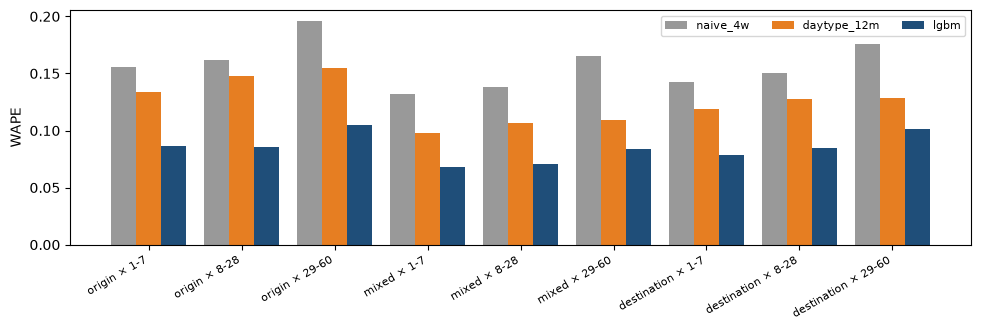

In [4]:
t = metrics.filter(pl.col("dimension") == "station_type x horizon_bucket").pivot(
    on="model", index="group", values="wape"
)
order = [f"{s} × {b}" for s in ["origin", "mixed", "destination"] for b in ["1-7", "8-28", "29-60"]]
t = pl.DataFrame({"group": order}).join(t, on="group", how="left")
fig, ax = plt.subplots(figsize=(10, 3.4))
w = 0.27
for i, m in enumerate(MODELS):
    ax.bar([x + (i - 1) * w for x in range(len(order))], t[m], w, label=m, color=COLORS[m])
ax.set_xticks(range(len(order)), order, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("WAPE")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
t

## 4. WAPE by origin
Summer origins (July–September) are the hardest: the summer dip, station closures for works and the post-break September level.

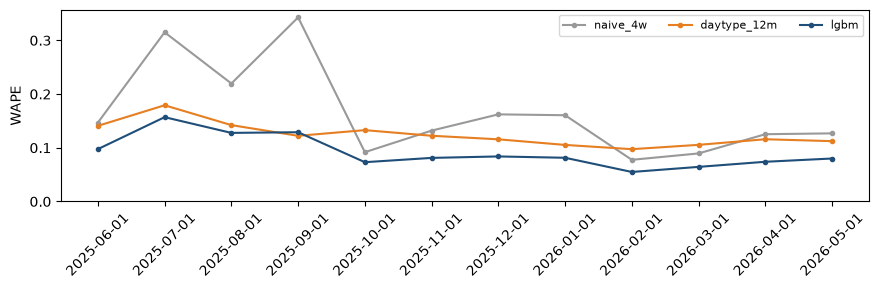

In [5]:
o = (
    metrics.filter(pl.col("dimension") == "origin")
    .pivot(on="model", index="group", values="wape")
    .sort("group")
)
fig, ax = plt.subplots(figsize=(9, 3))
for m in MODELS:
    ax.plot(o["group"], o[m], marker="o", ms=3, label=m, color=COLORS[m])
ax.set_ylabel("WAPE")
ax.set_ylim(0)
ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()

## 5. Network daily totals for two origins

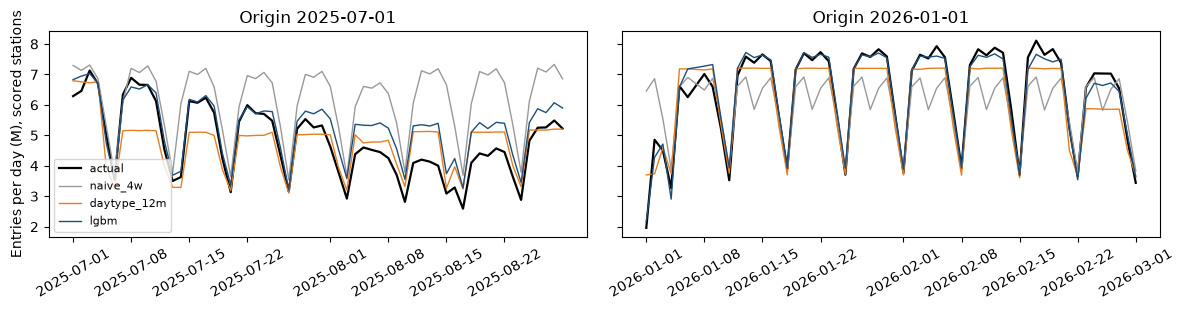

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, origin in zip(axes, sorted(pred["origin"].unique())[1::6], strict=True):
    s = vb.network_series(pred, origin, MODELS)
    ax.plot(s["date"], s["y"] / 1e6, color="black", lw=1.6, label="actual")
    for m in MODELS[:3]:
        ax.plot(s["date"], s[m] / 1e6, color=COLORS[m], lw=1, label=m)
    ax.set_title(f"Origin {origin}")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Entries per day (M), scored stations")
axes[0].legend(fontsize=8)
plt.tight_layout()

## 6. Where the LightGBM error comes from
Largest station × origin contributions. Large relative bias = works starting after the origin, or a counting change (Gare du Nord, Haussmann Saint-Lazare, Magenta jump in the 2026 Q1 file).

In [7]:
vb.station_bias(pred, "lgbm", 12).with_columns(
    pl.col("station_id").replace_strict(names, default=None).alias("name")
)

origin,station_id,share_of_error,rel_bias,name
date,i64,f64,f64,str
2026-01-01,71410,0.118259,0.339779,"""Gare du Nord"""
2025-12-01,71410,0.060043,0.203388,"""Gare du Nord"""
2025-07-01,71370,0.047914,-0.191006,"""Gare Saint-Lazare"""
2025-09-01,71370,0.045862,0.156457,"""Gare Saint-Lazare"""
2025-10-01,71517,0.042855,0.109892,"""La Défense"""
2026-01-01,73688,0.038014,0.440693,"""Haussmann Saint-Lazare"""
2026-03-01,71410,0.037302,0.073262,"""Gare du Nord"""
2025-06-01,71139,0.036755,0.164998,"""Gare Montparnasse"""
2026-02-01,71410,0.036398,0.063498,"""Gare du Nord"""


## 7. Feature importance (mean gain share over origins)

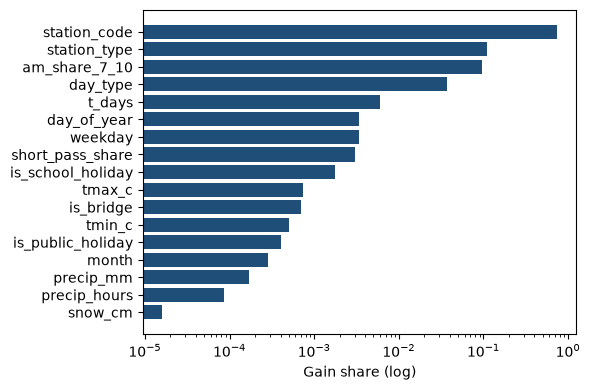

In [8]:
imp = (
    importance.group_by("feature")
    .agg(pl.col("gain").mean())
    .with_columns((pl.col("gain") / pl.col("gain").sum()).alias("share"))
    .sort("share")
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(imp["feature"], imp["share"], color="#1f4e79")
ax.set_xscale("log")
ax.set_xlabel("Gain share (log)")
plt.tight_layout()

## 8. Option B — 80 % intervals and busy-day probability
Calibration = forecast log: out-of-sample forecasts of earlier origins (12 warm-up origins before
the first scored one) for clean days of the 365 days before each origin. `conformal` = point
forecast + residual quantiles; `cqr` = conformalized LightGBM quantiles; `quantile` = raw.

In [9]:
intervals.filter(pl.col("dimension").is_in(["overall", "horizon_bucket"])).select(
    "dimension", "group", "method", "coverage", "rel_width", "interval_score"
)

dimension,group,method,coverage,rel_width,interval_score
str,str,str,f64,f64,f64
"""overall""","""all""","""conformal""",0.810317,0.317461,0.494114
"""overall""","""all""","""cqr""",0.807377,0.39022,0.55685
"""overall""","""all""","""quantile""",0.577041,0.258615,0.616585
"""horizon_bucket""","""1-7""","""conformal""",0.810119,0.272969,0.425145
"""horizon_bucket""","""29-60""","""conformal""",0.806926,0.347559,0.540436
"""horizon_bucket""","""8-28""","""conformal""",0.815537,0.286308,0.446326
"""horizon_bucket""","""1-7""","""cqr""",0.804074,0.354452,0.483995
"""horizon_bucket""","""29-60""","""cqr""",0.807049,0.413487,0.595848
"""horizon_bucket""","""8-28""","""cqr""",0.808976,0.366578,0.521384


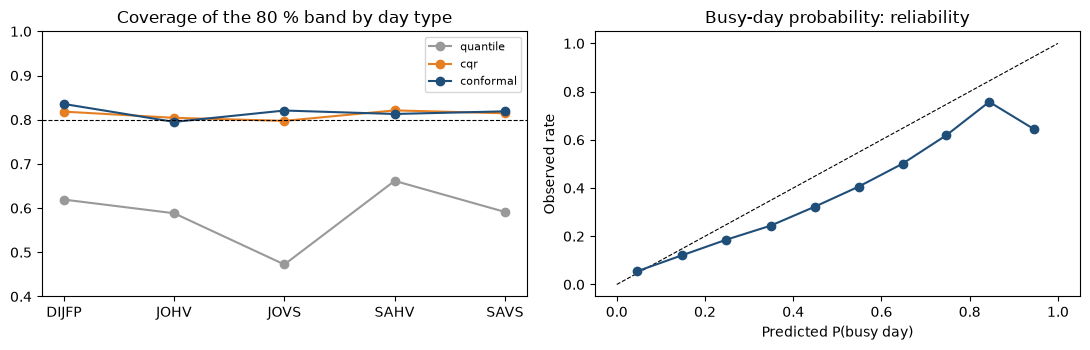

In [10]:
from idf_crowding.models import intervals as iv

scored = pred.filter(pl.col("scored"))
rel = iv.reliability(scored)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cov = intervals.filter(pl.col("dimension") == "day_type")
for m, c in [("quantile", "#999999"), ("cqr", "#e67e22"), ("conformal", "#1f4e79")]:
    d = cov.filter(pl.col("method") == m).sort("group")
    axes[0].plot(d["group"], d["coverage"], marker="o", label=m, color=c)
axes[0].axhline(0.8, color="black", lw=0.8, ls="--")
axes[0].set_ylim(0.4, 1)
axes[0].set_title("Coverage of the 80 % band by day type")
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], color="black", lw=0.8, ls="--")
axes[1].plot(rel["mean_p"], rel["observed"], marker="o", color="#1f4e79")
axes[1].set_xlabel("Predicted P(busy day)")
axes[1].set_ylabel("Observed rate")
axes[1].set_title("Busy-day probability: reliability")
plt.tight_layout()

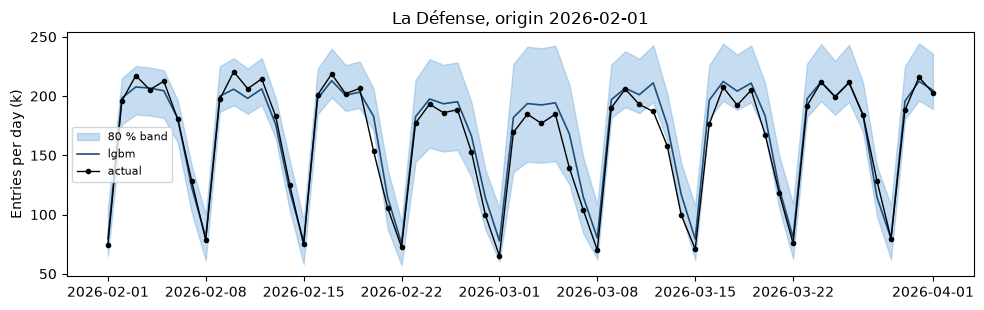

In [11]:
origin = sorted(pred["origin"].unique())[8]
sid = 71517  # La Défense
b = vb.station_band(pred, sid, origin)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(
    b["date"], b["conf_lo"] / 1e3, b["conf_hi"] / 1e3, color="#6fa8dc", alpha=0.4, label="80 % band"
)
ax.plot(b["date"], b["lgbm"] / 1e3, color="#1f4e79", lw=1.2, label="lgbm")
ax.plot(b["date"], b["y"] / 1e3, color="black", lw=1, marker=".", label="actual")
ax.set_title(f"{names[sid]}, origin {origin}")
ax.set_ylabel("Entries per day (k)")
ax.legend(fontsize=8)
plt.tight_layout()